# AI Smart Airport — estimation du risque de correspondance manquée

Le modèle est entraîné comme **un classifieur binaire** (cible : correspondance manquée,
0 ou 1). Sa sortie utilisée par le nœud de décision C est la probabilité de la classe 1
(predict_proba), qui sert de score de risque. Les données sont synthétiques : leurs
résultats ne sont pas une validation opérationnelle. La cible est simulée par la règle
experte et un bruit gaussien reproductible.

In [ ]:
from pathlib import Path
import importlib.metadata as metadata
import importlib.util
import logging
import sys
import time
import tempfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, brier_score_loss, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Le répertoire de travail peut être ai, la racine du projet ou celle du workspace.
candidates = [Path.cwd() / "ai", Path.cwd() / "Projet-STR" / "ai", Path.cwd()]
AI_DIR = next((p.resolve() for p in candidates if (p / "dataset_features.csv").is_file()), None)
if AI_DIR is None:
    raise FileNotFoundError("Lancer le notebook depuis ai, Projet-STR ou le workspace.")
sys.path.insert(0, str(AI_DIR))
print("Dossier de travail :", AI_DIR)

## 1. Chargement et exploration

Dimensions : (8000, 10)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
scheduled_buffer_min,8000.0,NaN,NaN,NaN,77.3165,22.840114,45.0,59.0,76.0,93.0,150.0
delay_min,8000.0,NaN,NaN,NaN,19.7695,12.813358,1.0,11.0,16.0,25.0,90.0
connecting_pax,8000.0,NaN,NaN,NaN,32.188,21.765256,1.0,17.0,27.0,42.0,179.0
gate_distance_m,8000.0,NaN,NaN,NaN,380.0125,198.992163,50.0,225.0,347.0,512.0,800.0
security_wait_min,8000.0,NaN,NaN,NaN,9.092087,6.593771,0.7,4.5,7.2,11.425,50.0
aircraft_type,8000,3,medium,4381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak_hour,8000.0,NaN,NaN,NaN,0.3545,0.478391,0.0,0.0,0.0,1.0,1.0
weather,8000,3,normal,5631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
buses_available,8000.0,NaN,NaN,NaN,3.50275,1.105054,0.0,3.0,4.0,4.0,5.0
connection_missed,8000.0,NaN,NaN,NaN,0.256375,0.436659,0.0,0.0,0.0,1.0,1.0


Valeurs manquantes :


,nombre
scheduled_buffer_min,0
delay_min,0
connecting_pax,0
gate_distance_m,0
security_wait_min,0
aircraft_type,0
peak_hour,0
weather,0
buses_available,0
connection_missed,0


,count,mean,std,min,25%,50%,75%,max
aircraft_type,,,,,,,,
large,1581.0,56.812777,26.759271,1.0,38.0,53.0,72.0,179.0
medium,4381.0,30.934718,15.108597,1.0,20.0,29.0,40.0,109.0
small,2038.0,15.779195,8.403387,1.0,9.0,15.0,21.0,48.0


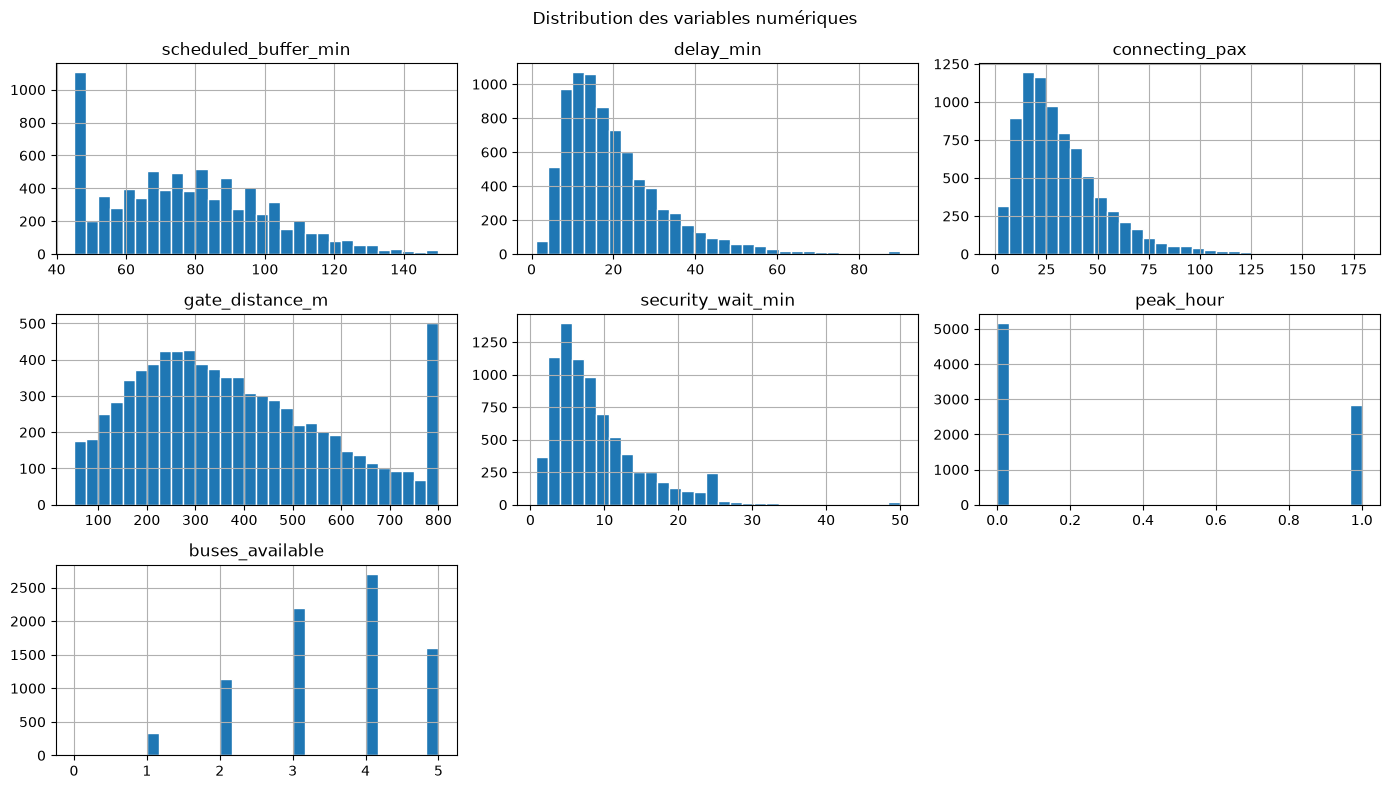

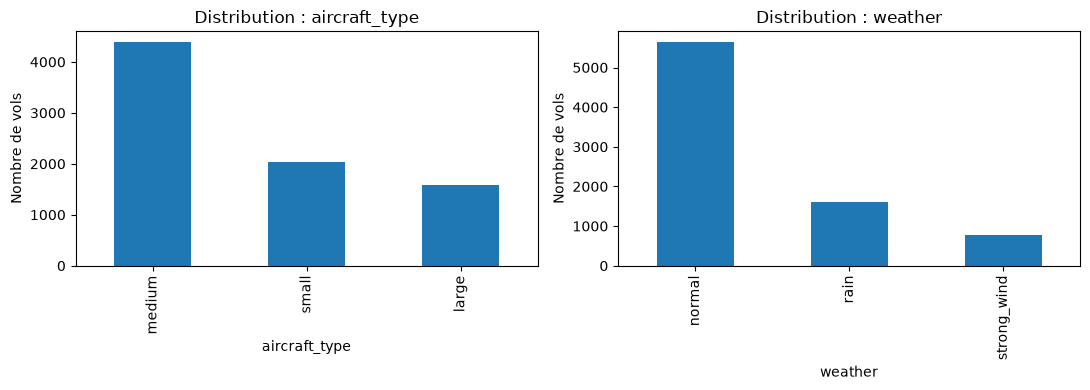

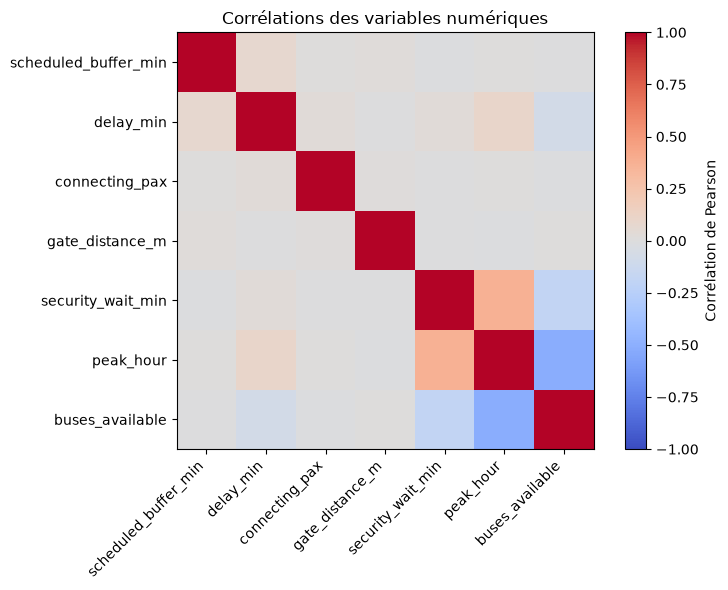

In [28]:
df = pd.read_csv(AI_DIR / "dataset_features.csv")
demo = pd.read_csv(AI_DIR / "demo_cases.csv")
raw_num = ["scheduled_buffer_min", "delay_min", "connecting_pax", "gate_distance_m",
           "security_wait_min", "peak_hour", "buses_available"]
cats = ["aircraft_type", "weather"]
raw_columns = raw_num + cats
missing_columns = set(raw_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Colonnes absentes : {sorted(missing_columns)}")
print("Dimensions :", df.shape)
display(df.describe(include="all").T)
print("Valeurs manquantes :")
display(df.isna().sum().to_frame("nombre"))
display(df.groupby("aircraft_type", observed=True)["connecting_pax"].describe())

df[raw_num].hist(figsize=(14, 8), bins=30, edgecolor="white")
plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, cats):
    df[name].value_counts(dropna=False).plot.bar(ax=ax)
    ax.set(title=f"Distribution : {name}", xlabel=name, ylabel="Nombre de vols")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[raw_num].corr()
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(raw_num)), raw_num, rotation=45, ha="right")
ax.set_yticks(range(len(raw_num)), raw_num)
ax.set_title("Corrélations des variables numériques")
fig.colorbar(im, ax=ax, label="Corrélation de Pearson")
plt.tight_layout()
plt.show()

## 2. Cible et risque de référence

La cible `connection_missed` est enregistrée dans le CSV avec les seules variables brutes.
Le score de risque du modèle est calculé à la demande, sans être stocké dans le CSV.
Le risque théorique sert uniquement à l'évaluation finale ; il n'est pas ajouté
aux données d'entraînement. Aucune variable dérivée de la formule n'est utilisée.

In [29]:
from label_rule import compute_label, true_risk

df = df[[col for col in df.columns if col in raw_columns]].copy()
df["connection_missed"] = compute_label(df, seed=SEED)
if df["connection_missed"].isna().any() or not set(df["connection_missed"].unique()).issubset({0, 1}):
    raise ValueError("compute_label doit renvoyer uniquement des valeurs binaires non manquantes.")
df.to_csv(AI_DIR / "dataset_features.csv", index=False)
print(f"Taux de classe 1 : {df['connection_missed'].mean():.2%}")

Taux de classe 1 : 25.64%


## 3. Séparation et prétraitement

Le découpage est stratifié ; chaque prétraitement est ajusté uniquement à
l'intérieur de son pli d'entraînement. Le test reste réservé à l'évaluation finale.

In [19]:
features = raw_columns.copy()
X = df[features].copy()
assert not {"connection_missed", "risk", "true_risk"} & set(X.columns)
if X.isna().any().any():
    raise ValueError("Les features d'entraînement contiennent des valeurs manquantes ; les traiter avant l'entraînement.")
y = df["connection_missed"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
risk_test = true_risk(df.loc[X_test.index])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"f1": "f1", "auc": "roc_auc", "brier": "neg_brier_score"}

def make_pipeline(columns, estimator):
    categorical = [c for c in columns if c in cats]
    numeric = [c for c in columns if c not in cats]
    transformer = ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ], remainder="drop")
    return Pipeline([("preprocessing", transformer), ("classifier", clone(estimator))])

def base_estimators():
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                 eval_metric="logloss", random_state=SEED, n_jobs=1),
    }

def cv_summary(estimator, features):
    result = cross_validate(estimator, X_train[features], y_train, cv=cv,
                            scoring=scoring, n_jobs=1, error_score="raise")
    output = {}
    for metric in scoring:
        values = result[f"test_{metric}"]
        if metric == "brier":
            values = -values
        output[f"{metric}_mean"] = values.mean()
        output[f"{metric}_std"] = values.std(ddof=1)
    return output
print("Train :", X_train.shape, "— test :", X_test.shape)

Train : (6400, 9) — test : (1600, 9)


## 4. Modèles individuels et ensembles

Les quatre modèles sont comparés sur des prédictions hors-fold du train. Chaque modèle reçoit
son propre seuil, le plus élevé permettant un rappel d'au moins RECALL_TARGET. Après examen des
métriques et matrices CV, l'utilisateur choisit le modèle ; son seuil associé sert à l'évaluation
finale. Le jeu de test n'intervient pas dans ces choix.

LogisticRegression : seuil CV=0.43, rappel=0.901, faux négatifs=162, faux positifs=215.
RandomForest : seuil CV=0.36, rappel=0.902, faux négatifs=161, faux positifs=380.
XGBoost : seuil CV=0.34, rappel=0.902, faux négatifs=161, faux positifs=308.
Voting soft : seuil CV=0.39, rappel=0.902, faux négatifs=160, faux positifs=265.


,modèle,seuil,faux négatifs,faux positifs,rappel classe 1,précision,F1,Brier CV
0,LogisticRegression,0.43,162,215,0.9013,0.8731,0.8870,0.0427
1,RandomForest,0.36,161,380,0.9019,0.7957,0.8455,0.0585
2,XGBoost,0.34,161,308,0.9019,0.8277,0.8632,0.0489
3,Voting soft,0.39,160,265,0.9025,0.8482,0.8745,0.0462


,modèle,seuil,faux négatifs,faux positifs,rappel classe 1,précision,F1,seuil retenu
0,LogisticRegression,0.10,27,696,0.9835,0.6987,0.8170,
1,LogisticRegression,0.15,51,545,0.9689,0.7447,0.8422,
2,LogisticRegression,0.20,70,454,0.9573,0.7758,0.8571,
3,LogisticRegression,0.25,96,395,0.9415,0.7964,0.8629,
4,LogisticRegression,0.30,122,329,0.9257,0.8220,0.8707,
...,...,...,...,...,...,...,...,...
67,Voting soft,0.70,427,67,0.7398,0.9477,0.8309,
68,Voting soft,0.75,495,50,0.6984,0.9582,0.8079,
69,Voting soft,0.80,580,34,0.6466,0.9689,0.7756,
70,Voting soft,0.85,697,20,0.5753,0.9793,0.7248,


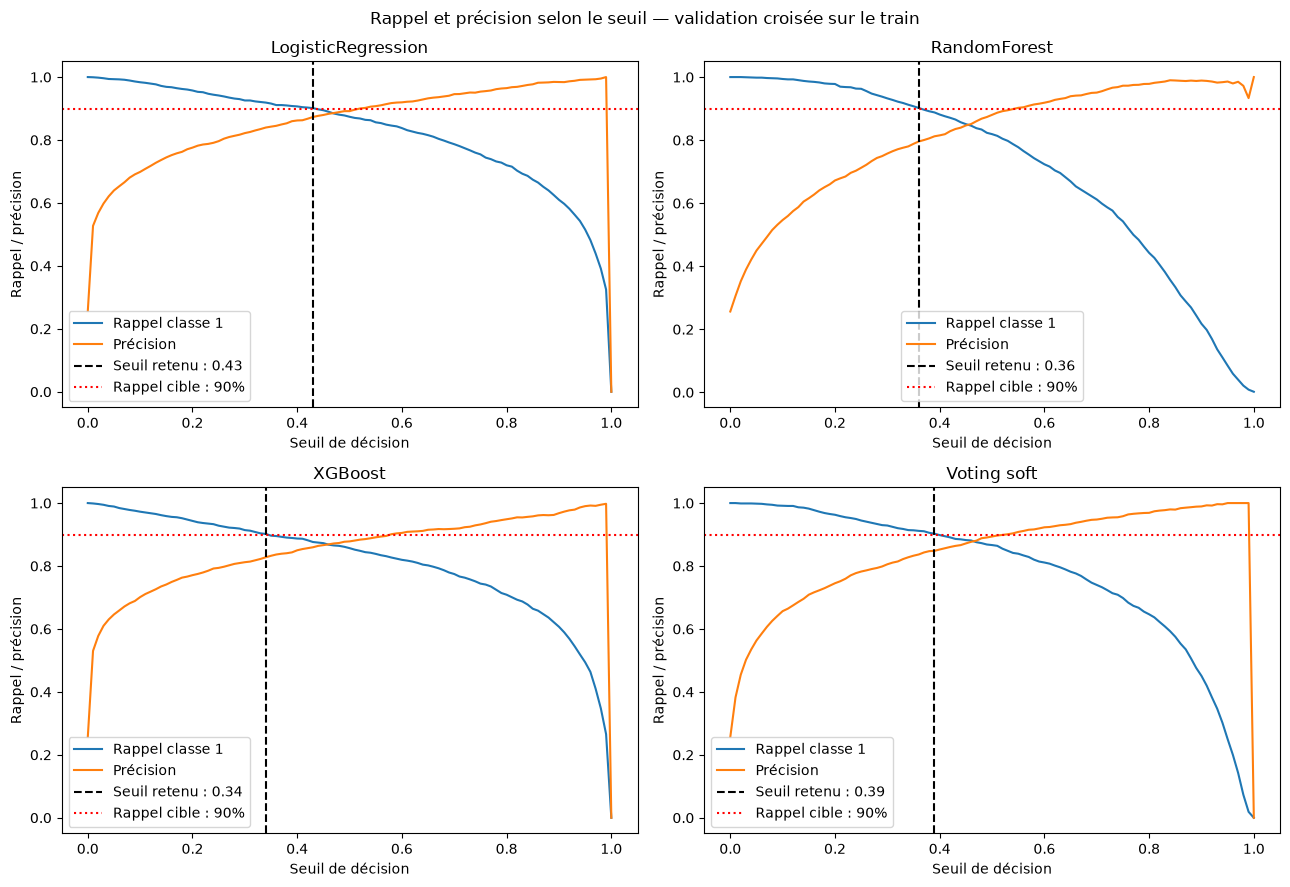

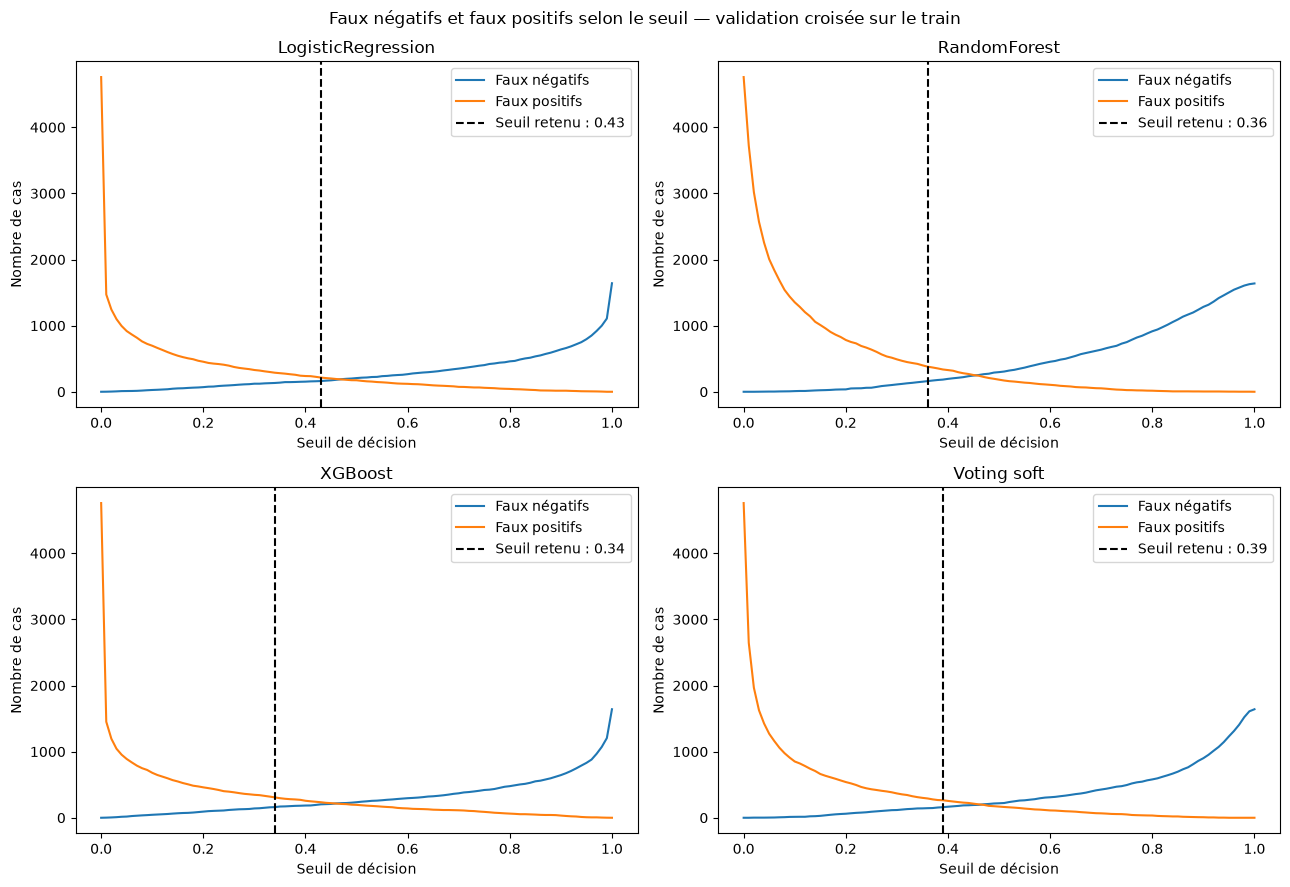

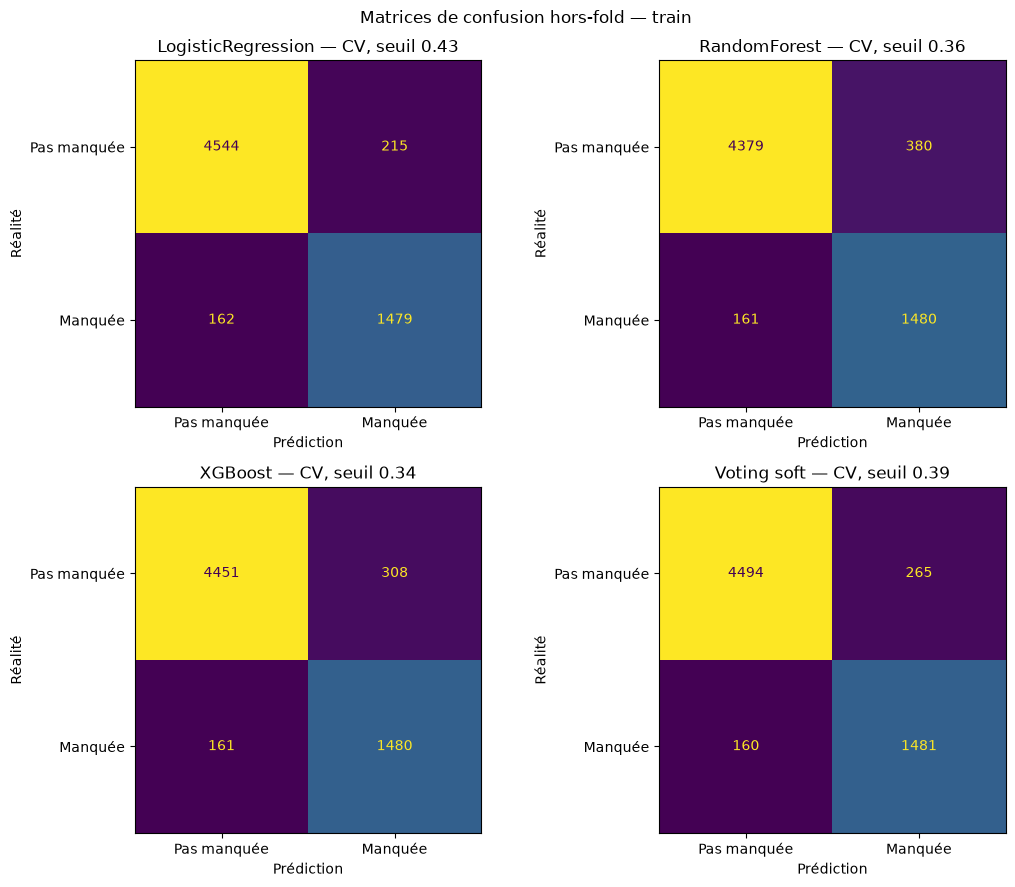

Modèle retenu : LogisticRegression, seuil CV associé : 0.43.


,évaluation,modèle,seuil,faux négatifs,faux positifs,rappel classe 1,précision,F1
0,Seuil retenu,LogisticRegression,0.43,40,59,0.9024,0.8625,0.8820
1,Seuil 0.50,LogisticRegression,0.50,51,50,0.8756,0.8778,0.8767


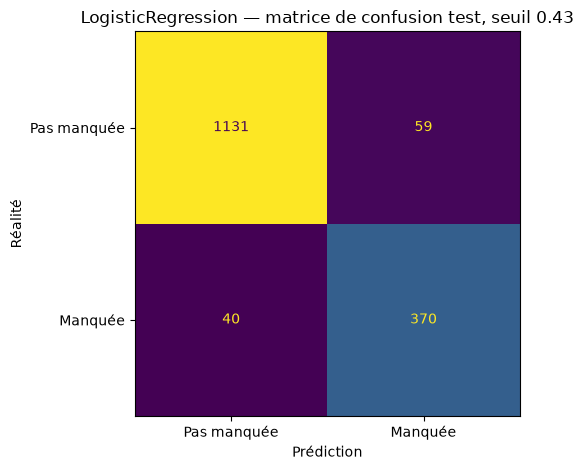

In [36]:
RECALL_TARGET = 0.90
MODEL_TO_USE = "LogisticRegression"

from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

if not (np.asarray(y_train) == 1).any() or not (np.asarray(y_train) == 0).any():
    raise ValueError("La validation requiert des exemples des deux classes dans y_train.")

base = base_estimators()
voting = VotingClassifier(estimators=[(name, clone(model)) for name, model in base.items()],
                          voting="soft", n_jobs=1)
estimators = {**base, "Voting soft": voting}
model_cv = {}
fitted_models = {}
cv_probabilities_by_model = {}
model_threshold_rows = []
threshold_grid = np.round(np.arange(0.00, 1.001, 0.01), 2)


def threshold_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "faux négatifs": int(fn),
        "faux positifs": int(fp),
        "rappel classe 1": recall_score(y_true, predictions, zero_division=0),
        "précision": precision_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
    }


for name, estimator in estimators.items():
    pipe = make_pipeline(features, estimator)
    model_cv[name] = cv_summary(pipe, features)
    cv_probabilities = cross_val_predict(
        pipe, X_train[features], y_train,
        cv=5, method="predict_proba", n_jobs=1
    )[:, list(np.unique(y_train)).index(1)]
    cv_probabilities_by_model[name] = cv_probabilities
    pipe.fit(X_train[features], y_train)
    fitted_models[name] = pipe

    cv_rows = [
        {"seuil": threshold, **threshold_metrics(y_train, cv_probabilities, threshold)}
        for threshold in threshold_grid
    ]
    eligible_thresholds = [
        row["seuil"] for row in cv_rows
        if row["rappel classe 1"] >= RECALL_TARGET
    ]
    if not eligible_thresholds:
        raise ValueError(f"Aucun seuil ne permet d'atteindre le rappel cible pour {name}.")
    model_threshold = max(eligible_thresholds)
    metrics = threshold_metrics(y_train, cv_probabilities, model_threshold)
    model_threshold_rows.append({
        "modèle": name,
        "seuil": model_threshold,
        **metrics,
        "Brier CV": model_cv[name]["brier_mean"],
    })
    print(f"{name} : seuil CV={model_threshold:.2f}, "
          f"rappel={metrics['rappel classe 1']:.3f}, "
          f"faux négatifs={metrics['faux négatifs']}, "
          f"faux positifs={metrics['faux positifs']}.")

display(pd.DataFrame(model_threshold_rows).round(4))



report_rows = []
base_report_thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
selected_thresholds = {row["modèle"]: row["seuil"] for row in model_threshold_rows}
for name, cv_probabilities in cv_probabilities_by_model.items():
    report_thresholds = base_report_thresholds.copy()
    if not np.isclose(report_thresholds, selected_thresholds[name]).any():
        report_thresholds = np.sort(np.append(report_thresholds, selected_thresholds[name]))
    for threshold in report_thresholds:
        report_rows.append({
            "modèle": name,
            "seuil": threshold,
            **threshold_metrics(y_train, cv_probabilities, threshold),
            "seuil retenu": "Oui" if np.isclose(threshold, selected_thresholds[name]) else "",
        })
display(pd.DataFrame(report_rows).round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, name in zip(axes.flat, cv_probabilities_by_model):
    cv_probabilities = cv_probabilities_by_model[name]
    rows = [threshold_metrics(y_train, cv_probabilities, threshold) for threshold in threshold_grid]
    ax.plot(threshold_grid, [row["rappel classe 1"] for row in rows], label="Rappel classe 1")
    ax.plot(threshold_grid, [row["précision"] for row in rows], label="Précision")
    ax.axvline(selected_thresholds[name], color="black", linestyle="--",
               label=f"Seuil retenu : {selected_thresholds[name]:.2f}")
    ax.axhline(RECALL_TARGET, color="red", linestyle=":", label=f"Rappel cible : {RECALL_TARGET:.0%}")
    ax.set_title(name)
    ax.set_xlabel("Seuil de décision")
    ax.set_ylabel("Rappel / précision")
    ax.legend()
fig.suptitle("Rappel et précision selon le seuil — validation croisée sur le train")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, name in zip(axes.flat, cv_probabilities_by_model):
    cv_probabilities = cv_probabilities_by_model[name]
    rows = [threshold_metrics(y_train, cv_probabilities, threshold) for threshold in threshold_grid]
    ax.plot(threshold_grid, [row["faux négatifs"] for row in rows], label="Faux négatifs")
    ax.plot(threshold_grid, [row["faux positifs"] for row in rows], label="Faux positifs")
    ax.axvline(selected_thresholds[name], color="black", linestyle="--",
               label=f"Seuil retenu : {selected_thresholds[name]:.2f}")
    ax.set_title(name)
    ax.set_xlabel("Seuil de décision")
    ax.set_ylabel("Nombre de cas")
    ax.legend()
fig.suptitle("Faux négatifs et faux positifs selon le seuil — validation croisée sur le train")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, cv_probabilities_by_model):
    cv_predictions = (cv_probabilities_by_model[name] >= selected_thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_train, cv_predictions,
        display_labels=["Pas manquée", "Manquée"], colorbar=False, values_format="d", ax=ax
    )
    ax.set_title(f"{name} — CV, seuil {selected_thresholds[name]:.2f}")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réalité")
fig.suptitle("Matrices de confusion hors-fold — train")
plt.tight_layout()
plt.show()

if MODEL_TO_USE not in fitted_models:
    raise ValueError(f"Modèle inconnu : {MODEL_TO_USE}. Choisir parmi : {', '.join(fitted_models)}.")
selected_name = MODEL_TO_USE
selected_threshold = selected_thresholds[selected_name]
selected_model = fitted_models[selected_name]
print(f"Modèle retenu : {selected_name}, seuil CV associé : {selected_threshold:.2f}.")
test_probabilities = selected_model.predict_proba(X_test[features])[:, list(selected_model.classes_).index(1)]
test_rows = []
for evaluation_name, threshold in (("Seuil retenu", selected_threshold), ("Seuil 0.50", 0.50)):
    test_rows.append({
        "évaluation": evaluation_name,
        "modèle": selected_name,
        "seuil": threshold,
        **threshold_metrics(y_test, test_probabilities, threshold),
    })
display(pd.DataFrame(test_rows).round(4))

selected_test_predictions = (test_probabilities >= selected_threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, selected_test_predictions,
    display_labels=["Pas manquée", "Manquée"], colorbar=False, values_format="d"
)
plt.title(f"{selected_name} — matrice de confusion test, seuil {selected_threshold:.2f}")
plt.xlabel("Prédiction")
plt.ylabel("Réalité")
plt.tight_layout()
plt.show()

## 5. Calibration et comparaison au risque de référence

Les graphiques et métriques ci-dessous décrivent les probabilités produites par les modèles.
Cette cellule ne modifie ni le modèle ni le seuil retenus.

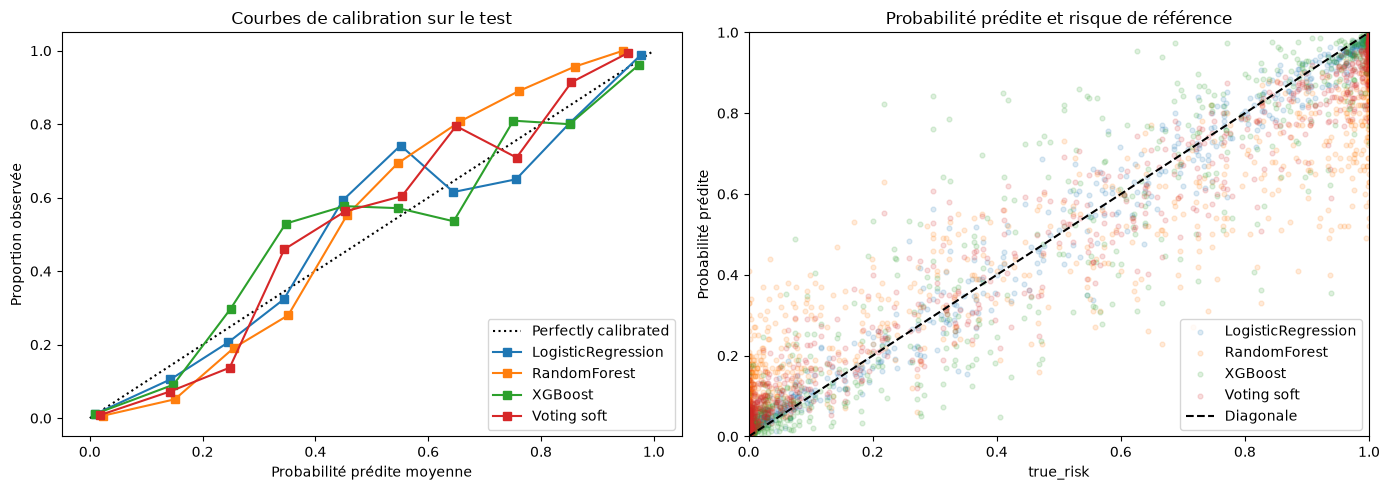

,modèle,Brier test,erreur absolue moyenne vs true_risk
0,LogisticRegression,0.0456,0.0138
1,RandomForest,0.0601,0.0796
2,XGBoost,0.0505,0.0346
3,Voting soft,0.0484,0.0376


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
calibration_rows = []
for name, model in fitted_models.items():
    p = model.predict_proba(X_test[features])[:, 1]
    CalibrationDisplay.from_predictions(y_test, p, n_bins=10, name=name, ax=axes[0])
    axes[1].scatter(risk_test, p, alpha=0.15, s=12, label=name)
    calibration_rows.append({"modèle": name, "Brier test": brier_score_loss(y_test, p),
                             "erreur absolue moyenne vs true_risk": np.mean(np.abs(p - risk_test))})
axes[0].set(title="Courbes de calibration sur le test",
            xlabel="Probabilité prédite moyenne", ylabel="Proportion observée")
axes[1].plot([0, 1], [0, 1], "k--", label="Diagonale")
axes[1].set(title="Probabilité prédite et risque de référence",
            xlabel="true_risk", ylabel="Probabilité prédite", xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(calibration_rows).round(4))

## 6. Importance par permutation

Calcul sur le test, avec le Brier négatif comme score : les importances sont
calculées sur les colonnes d'origine, avant transformation.

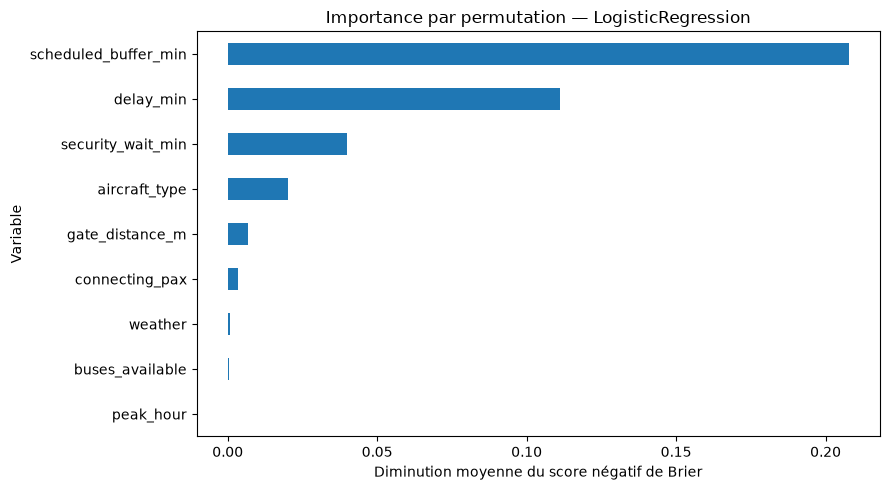

In [38]:
# Pour l'instant, j'ai choisi la régression logistique ; ce choix pourra changer si le feature engineering rend un autre modèle plus performant.
permutation = permutation_importance(
    selected_model, X_test[features], y_test, scoring="neg_brier_score",
    n_repeats=5, random_state=SEED, n_jobs=1
)
importance = pd.Series(permutation.importances_mean, index=features).sort_values()
importance.plot.barh(figsize=(9, 5), title=f"Importance par permutation — {selected_name}")
plt.xlabel("Diminution moyenne du score négatif de Brier")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 7. Temps d'inférence et de chargement

1 000 appels unitaires par modèle, incluant la construction d'une ligne brute ;
le maximum et le percentile 99 sont sensibles à la machine et à sa charge.
Le chargement est mesuré depuis un fichier temporaire.

In [39]:
timed_models = {name: (model, features)
                for name, model in fitted_models.items()}
timed_models["Modèle retenu final"] = (selected_model, features)
timing_rows = []
for name, (model, cols) in timed_models.items():
    with tempfile.TemporaryDirectory() as temp_dir:
        path = Path(temp_dir) / "model.joblib"
        joblib.dump(model, path)
        start = time.perf_counter()
        loaded = joblib.load(path)
        load_ms = (time.perf_counter() - start) * 1000
    durations = []
    for i in range(1000):
        raw_one = X_test.iloc[[i % len(X_test)]][raw_columns]
        start = time.perf_counter()
        one = raw_one
        loaded.predict_proba(one[cols])[:, 1]
        durations.append((time.perf_counter() - start) * 1000)
    mean_ms, max_ms, p99_ms = np.mean(durations), np.max(durations), np.percentile(durations, 99)
    timing_rows.append({"modèle": name, "moyenne ms": mean_ms, "maximum ms": max_ms,
                        "p99 ms": p99_ms, "chargement ms": load_ms,
                        "3 mesures < 200 ms": all(v < 200 for v in (mean_ms, max_ms, p99_ms))})
display(pd.DataFrame(timing_rows).round(3))
if not all(row["3 mesures < 200 ms"] for row in timing_rows):
    print("Attention : au moins un modèle dépasse le seuil d'inférence de 200 ms.")

,modèle,moyenne ms,maximum ms,p99 ms,chargement ms,3 mesures < 200 ms
0,LogisticRegression,3.977,9.607,7.383,12.855,True
1,RandomForest,10.536,32.051,18.120,76.161,True
2,XGBoost,5.022,10.606,8.666,35.752,True
3,Voting soft,11.572,20.146,18.100,63.640,True
4,Modèle retenu final,3.775,8.326,6.401,6.117,True


## 8. Cas de démonstration

Le risque théorique est affiché à titre de référence, indépendamment du modèle.

In [40]:
demo_risk = np.asarray(true_risk(demo))
if len(demo_risk) != len(demo) or not np.isfinite(demo_risk).all() or ((demo_risk < 0) | (demo_risk > 1)).any():
    raise ValueError("true_risk doit fournir une probabilité valide par vol de démo.")
demo_prob = selected_model.predict_proba(demo[features])[:, 1]
demo_results = pd.DataFrame({
    "flight": demo["flight"], "probabilité": demo_prob, "true_risk": demo_risk,
    "niveau": np.where(demo_prob < 0.50, "faible", np.where(demo_prob < 0.80, "moyen", "critique"))
})
display(demo_results.round(4))

,flight,probabilité,true_risk,niveau
0,TU701,0.8331,0.8779,critique
1,TU702,0.0000,0.0000,faible
2,TU703,0.2525,0.3014,faible


## 9. Export et interface d'inférence

Le modèle complet est sérialisé avec ses colonnes et les valeurs de remplacement
apprises uniquement sur le train. `predict` charge ce fichier une fois par processus.
Les catégories inconnues restent acceptées par `OneHotEncoder`.

Les fichiers joblib ne doivent être chargés que s'ils proviennent d'une source fiable.

In [43]:
model_dir = AI_DIR / "model"
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "risk_model.joblib"

# Modèle livré au nœud B (predict.py accepte n'importe quel modèle scikit-learn avec predict_proba)
final_model = fitted_models["LogisticRegression"]
final_model.risk_feature_columns_ = list(features)
final_model.risk_raw_columns_ = list(raw_columns)
final_model.risk_defaults_ = {
    **{c: float(X_train[c].median()) for c in raw_num},
    "aircraft_type": X_train["aircraft_type"].mode().iloc[0],
    "weather": "normal", "peak_hour": 0, "buses_available": 5,
}
joblib.dump(final_model, model_path)
print("Modèle exporté :", model_path)

# Contrôle avec la vraie fonction du nœud B
from predict import predict
for _, row in demo.iterrows():
    print(row["flight"], predict(row[raw_columns].to_dict()))

Modèle exporté : C:\Users\MalekAzri\STR AIRPORT\Projet-STR\ai\model\risk_model.joblib
TU701 {'risk': 0.8330651906026894}
TU702 {'risk': 1.0858940876154099e-07}
TU703 {'risk': 0.25253855617215676}


### Versions exactes de l'environnement

Le fichier est généré à partir des distributions installées. Il inclut aussi
Matplotlib et les outils nécessaires à l'exécution Jupyter.

In [44]:
packages = ["numpy", "pandas", "scikit-learn", "xgboost", "joblib", "scipy",
            "matplotlib", "ipykernel", "nbformat", "nbclient"]
requirements = "\n".join(f"{package}=={metadata.version(package)}" for package in packages) + "\n"
(AI_DIR / "requirements.txt").write_text(requirements, encoding="utf-8")
print(requirements)

numpy==2.5.5
pandas==3.1.1
scikit-learn==1.9.1
xgboost==3.4.1
joblib==1.6.0
scipy==1.18.1
matplotlib==3.11.2
ipykernel==7.4.0
nbformat==5.11.1
nbclient==0.11.0

